R² Score on Training Data: 0.6654
Mean Absolute Error: 32.0935
Root Mean Squared Error: 43.5930


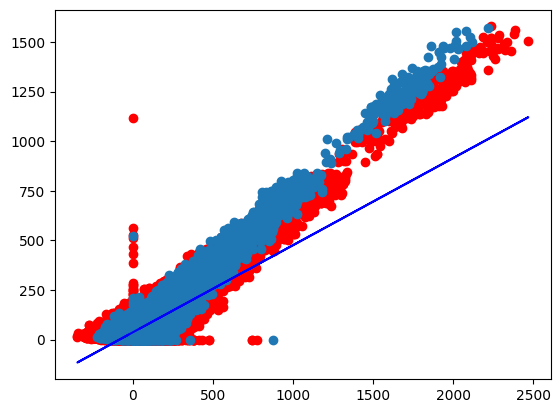

In [2]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt


train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

train = train.dropna()
test = test.dropna()

X_train = train['open'].values
y_train = train['close'].values
X_test = test['open'].values

#Add bias column (for intercept)
X_train = np.c_[np.ones(X_train.shape[0]), X_train]
X_test = np.c_[np.ones(X_test.shape[0]), X_test]

#Compute weights using matrix method
# w = (X^T X)^(-1) X^T y
w = np.linalg.inv(X_train.T.dot(X_train)).dot(X_train.T).dot(y_train)


y_pred_train = X_train.dot(w)

#Compute accuracy metrics manually
ss_res = np.sum((y_train - y_pred_train)**2)
ss_tot = np.sum((y_train - np.mean(y_train))**2)
r2_score = 1 - (ss_res / ss_tot)

mae = np.mean(np.abs(y_train - y_pred_train))
rmse = np.sqrt(np.mean((y_train - y_pred_train)**2))

print(f"R² Score on Training Data: {r2_score:.4f}")
print(f"Mean Absolute Error: {mae:.4f}")
print(f"Root Mean Squared Error: {rmse:.4f}")

predicted_close = X_test.dot(w)
test['Predicted_Close'] = predicted_close
plt.scatter(train['open'], train['close'],color='red')
plt.scatter(test['open'], test['close'])
plt.plot(train['open'], y_pred_train,color='blue')
plt.show()
